# 02. Entrenamiento y evaluación

Se compara la Regresión Logística con `DummyClassifier` (baseline `most_frequent`) y un Árbol de Decisión acotado. La etiqueta positiva es `>50K`. La separación es estratificada 80/20 con `random_state=42`; el test se reserva para la evaluación final.


In [1]:
from pathlib import Path
import sys
ROOT = next(path for path in (Path.cwd(), *Path.cwd().parents) if (path / "src" / "utils.py").exists())
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display
from sklearn.model_selection import train_test_split
from src.utils import (
    RANDOM_STATE, calcular_metricas, cargar_datos, construir_pipeline_completo,
    graficar_confusion, identificar_columnas, obtener_features_y_objetivo,
    tabla_comparativa,
)


## 1. Preparación y división

Las categorías y los estadísticos de imputación se aprenden solo en train, dentro del pipeline.


In [2]:
df = cargar_datos()
X, y = obtener_features_y_objetivo(df)
numericas, categoricas = identificar_columnas(X)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)
print(f"Train: {len(X_train):,} filas | Test: {len(X_test):,} filas")
print(f"Predictores: {len(numericas)} numéricos y {len(categoricas)} categóricos")
print(f"Proporción positiva train/test: {y_train.mean():.4f} / {y_test.mean():.4f}")


Train: 39,073 filas | Test: 9,769 filas
Predictores: 5 numéricos y 8 categóricos
Proporción positiva train/test: 0.2393 / 0.2393


## 2. Modelos y entrenamiento

El preprocesamiento usa mediana para datos numéricos, moda para categorías, `StandardScaler` para variables numéricas y `OneHotEncoder` para categorías. El baseline no aprende relaciones entre las variables.


In [3]:
pipelines = {
    "Regresión Logística": construir_pipeline_completo(numericas, categoricas, "logistica"),
    "Árbol de Decisión": construir_pipeline_completo(numericas, categoricas, "arbol"),
    "Baseline (DummyClassifier)": construir_pipeline_completo(numericas, categoricas, "dummy"),
}
predicciones = {}
for nombre, pipeline in pipelines.items():
    pipeline.fit(X_train, y_train)
    predicciones[nombre] = pipeline.predict(X_test)
    print(f"Entrenado: {nombre}")


Entrenado: Regresión Logística


Entrenado: Árbol de Decisión


Entrenado: Baseline (DummyClassifier)


## 3. Métricas

- **Accuracy:** fracción total de predicciones correctas.
- **Precision:** de las predicciones >50K, qué proporción realmente supera ese umbral.
- **Recall:** de las personas que realmente superan el umbral, qué proporción detecta el modelo.
- **F1:** media armónica de precision y recall.


In [4]:
metricas = [calcular_metricas(y_test, y_pred, nombre) for nombre, y_pred in predicciones.items()]
tabla = tabla_comparativa(metricas)
tabla.to_csv(ROOT / "data" / "tabla_metricas.csv", encoding="utf-8-sig")
display(tabla)


,Accuracy,Precision,Recall,F1-Score
Modelo,,,,
Regresión Logística,0.8056,0.5632,0.8370,0.6733
Árbol de Decisión,0.7806,0.5248,0.8824,0.6582
Baseline (DummyClassifier),0.7607,0.0000,0.0000,0.0000


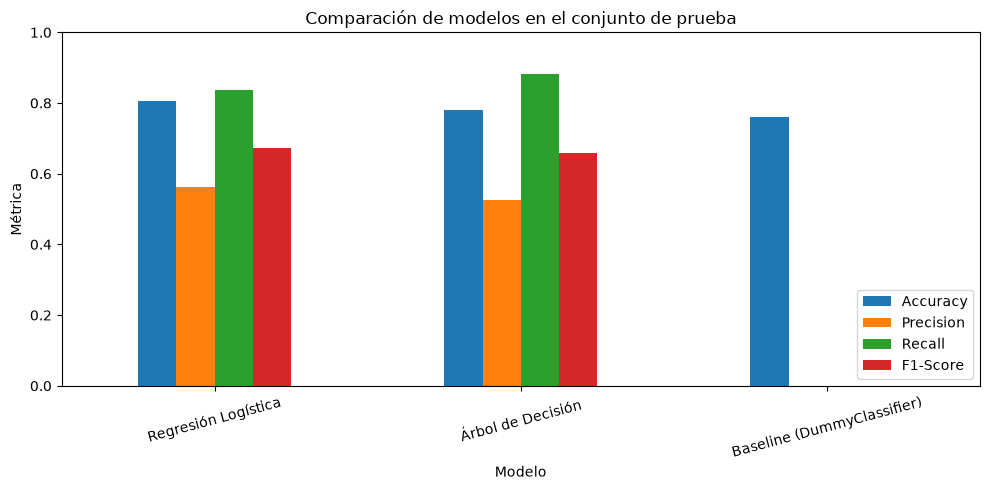

In [5]:
ax = tabla[["Accuracy", "Precision", "Recall", "F1-Score"]].plot(kind="bar", figsize=(10, 5))
ax.set_title("Comparación de modelos en el conjunto de prueba")
ax.set_ylabel("Métrica")
ax.set_ylim(0, 1)
ax.tick_params(axis="x", rotation=15)
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()


## 4. Matriz de confusión de la Regresión Logística

Las filas representan la etiqueta real y las columnas la predicción. VP: ingreso >50K detectado; VN: ingreso <=50K identificado; FP: predicción >50K cuando el valor real es <=50K; FN: ingreso >50K que el modelo no detecta.


,Predicho <=50K,Predicho >50K
Real <=50K,5913,1518
Real >50K,381,1957


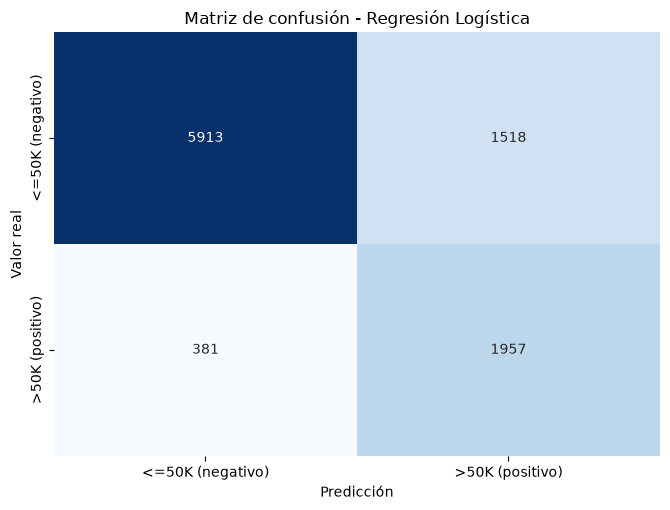

VN=5,913; FP=1,518; FN=381; VP=1,957


In [6]:
fig, cm = graficar_confusion(
    y_test, predicciones["Regresión Logística"], "Regresión Logística",
    ruta_guardado="data/confusion_lr.png",
)
display(pd.DataFrame(cm, index=["Real <=50K", "Real >50K"], columns=["Predicho <=50K", "Predicho >50K"]))
plt.show()
tn, fp, fn, vp = cm.ravel()
print(f"VN={tn:,}; FP={fp:,}; FN={fn:,}; VP={vp:,}")


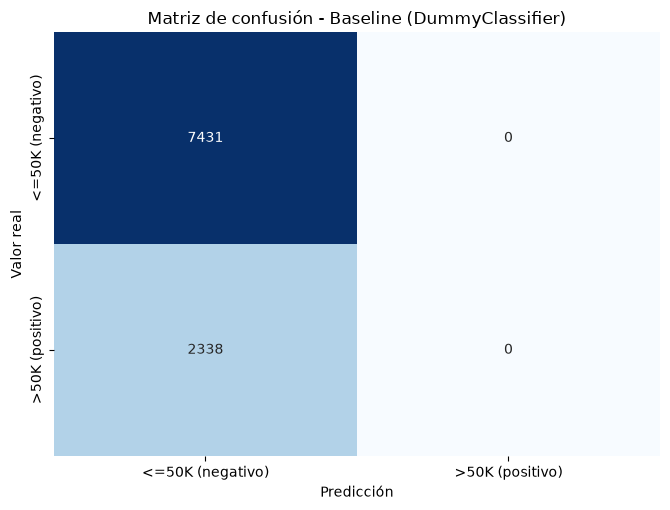

In [7]:
fig_dummy, cm_dummy = graficar_confusion(
    y_test, predicciones["Baseline (DummyClassifier)"], "Baseline (DummyClassifier)",
    ruta_guardado="data/confusion_dummy.png",
)
plt.show()


## 5. Criterios de aceptación

Criterios definidos antes de interpretar los resultados: accuracy > 0.75, F1 > 0.60, recall de la clase >50K > 0.55 y superar al baseline en las cuatro métricas. Estos umbrales son académicos; no validan el uso del modelo en decisiones reales.


In [8]:
lr = tabla.loc["Regresión Logística"]
dummy = tabla.loc["Baseline (DummyClassifier)"]
criterios = {
    "Accuracy > 0.75": lr["Accuracy"] > 0.75,
    "F1-Score > 0.60": lr["F1-Score"] > 0.60,
    "Recall > 0.55": lr["Recall"] > 0.55,
    "Supera baseline en las cuatro métricas": bool((lr > dummy).all()),
}
display(pd.DataFrame({"Criterio": criterios.keys(), "Cumple": criterios.values()}))
assert all(criterios.values()), "La Regresión Logística no cumple todos los criterios definidos."


,Criterio,Cumple
0,Accuracy > 0.75,True
1,F1-Score > 0.60,True
2,Recall > 0.55,True
3,Supera baseline en las cuatro métricas,True


## 6. Interpretación

La regresión logística ofrece un compromiso entre precision y recall. El baseline muestra por qué accuracy por sí sola puede ser engañosa con clases desbalanceadas. El notebook 03 vuelve a entrenar exactamente el mismo pipeline y audita recall y tasas positivas por sexo, raza y edad.
